# Skills Matching

## Исходные данные:
- **Вакансии:** `5_vacancies.csv`
- **Резюме:** `CV/1.docx` - `CV/30.docx`
- **Аннотации:** `annotations-for-the-first-30-vacancies.txt`

## Особенности ноутбука:
- Веса не заданы вручную, а рассчитываются на основе корреляционного анализа
- Корреляционный анализ: какие предикторы важны для каждого аннотатора
- Корреляционный анализ: какие предикторы использует модель

## Оценка:
1. Модель vs Аннотатор 1
2. Модель vs Аннотатор 2
3. Модель vs Консенсус
4. Аннотатор 1 vs Аннотатор 2 (и наоборот)

In [82]:
# =============================================================================
# УСТАНОВКА ЗАВИСИМОСТЕЙ
# =============================================================================

!pip install python-docx pandas numpy scipy matplotlib seaborn -q

import pandas as pd
import numpy as np
from scipy import stats
import re
import os
from docx import Document
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("Библиотеки загружены")

Библиотеки загружены


---
## 1. Загрузка данных из Google Drive

In [83]:
# =============================================================================
# ЗАГРУЗКА ДАННЫХ ИЗ GOOGLE DRIVE
# =============================================================================

from google.colab import drive
drive.mount('/content/drive')

# Путь к папке с данными в Google Drive
DATA_FOLDER = "/content/drive/MyDrive/vacancy-resume-matching-dataset"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [84]:
# =============================================================================
# КОНФИГУРАЦИЯ ПУТЕЙ
# =============================================================================

VACANCIES_PATH = os.path.join(DATA_FOLDER, "5_vacancies.csv")
ANNOTATIONS_PATH = os.path.join(DATA_FOLDER, "annotations-for-the-first-30-vacancies.txt")
CV_FOLDER = os.path.join(DATA_FOLDER, "CV")

# Проверка существования файлов
print("Проверка файлов:")
print(f"  Вакансии: {'ОК' if os.path.exists(VACANCIES_PATH) else 'FALSE'} {VACANCIES_PATH}")
print(f"  Аннотации: {'ОК' if os.path.exists(ANNOTATIONS_PATH) else 'FALSE'} {ANNOTATIONS_PATH}")
print(f"  Папка CV: {'ОК' if os.path.exists(CV_FOLDER) else 'FALSE'} {CV_FOLDER}")

# Если папка CV не существует, ищем docx в корне
if not os.path.exists(CV_FOLDER):
    CV_FOLDER = DATA_FOLDER
    print(f"Ищем docx файлы в: {CV_FOLDER}")

N_RESUMES = 30
N_VACANCIES = 5

Проверка файлов:
  Вакансии: ОК /content/drive/MyDrive/vacancy-resume-matching-dataset/5_vacancies.csv
  Аннотации: ОК /content/drive/MyDrive/vacancy-resume-matching-dataset/annotations-for-the-first-30-vacancies.txt
  Папка CV: ОК /content/drive/MyDrive/vacancy-resume-matching-dataset/CV


In [85]:
# =============================================================================
# ЗАГРУЗКА ВАКАНСИЙ
# =============================================================================

vacancies_df = pd.read_csv(VACANCIES_PATH)
print(f"Загружено вакансий: {len(vacancies_df)}")
print(f"Столбцы: {list(vacancies_df.columns)}")
print(f"\nНазвания вакансий:")
for i, row in vacancies_df.iterrows():
    print(f"  V{i+1}: {row['job_title']}")

Загружено вакансий: 5
Столбцы: ['id', 'job_description', 'job_title', 'uid']

Названия вакансий:
  V1: Software Developer - .Net
  V2: Remote Software Developer
  V3: Junior Level Software Developer (1-4 years experience)
  V4: Backend Software Developer
  V5: Software Developer


In [86]:
# =============================================================================
# ЗАГРУЗКА РЕЗЮМЕ ИЗ DOCX
# =============================================================================

def read_docx(filepath):
    """Читает текст из .docx файла."""
    try:
        doc = Document(filepath)
        full_text = []
        for para in doc.paragraphs:
            full_text.append(para.text)
        for table in doc.tables:
            for row in table.rows:
                for cell in row.cells:
                    full_text.append(cell.text)
        return '\n'.join(full_text)
    except Exception as e:
        print(f"Ошибка чтения {filepath}: {e}")
        return ""

resumes = {}
missing_files = []

for i in range(1, N_RESUMES + 1):
    filepath = os.path.join(CV_FOLDER, f"{i}.docx")
    if os.path.exists(filepath):
        resumes[i] = read_docx(filepath)
    else:
        missing_files.append(i)

print(f"Загружено резюме: {len(resumes)}")
if missing_files:
    print(f"Не найдены файлы для CV: {missing_files[:10]}{'...' if len(missing_files) > 10 else ''}")

Загружено резюме: 30


In [87]:
# =============================================================================
# ЗАГРУЗКА АННОТАЦИЙ
# =============================================================================

def parse_annotations(filepath):
    """Парсит файл аннотаций."""
    with open(filepath, 'r', encoding='utf-8') as f:
        content = f.read()

    def extract_arrays(text):
        arrays = re.findall(r'\[([\d,\s]+)\]', text)
        result = []
        for arr in arrays:
            nums = [int(x.strip()) for x in arr.split(',') if x.strip()]
            if len(nums) == 5:
                result.append(nums)
        return result

    lines = content.split('\n')
    ann1_rankings = []
    ann2_rankings = []
    current_annotator = None

    for line in lines:
        if 'ANNOTATOR_1' in line:
            current_annotator = 1
        elif 'ANNOTATOR_2' in line:
            current_annotator = 2

        arrays = extract_arrays(line)
        if arrays:
            if current_annotator == 1:
                ann1_rankings.extend(arrays)
            elif current_annotator == 2:
                ann2_rankings.extend(arrays)

    return ann1_rankings, ann2_rankings

ann1_rankings, ann2_rankings = parse_annotations(ANNOTATIONS_PATH)

print(f"Аннотатор 1: {len(ann1_rankings)} записей")
print(f"Аннотатор 2: {len(ann2_rankings)} записей")

Аннотатор 1: 30 записей
Аннотатор 2: 30 записей


---
## 2. Паттерны для извлечения таргетов

In [88]:
# =============================================================================
# ПАТТЕРНЫ ДЛЯ ИЗВЛЕЧЕНИЯ ТАРГЕТОВ
# =============================================================================

# --- PROGRAMMING LANGUAGES ---
PROGRAMMING_LANGUAGES = {
    'python': r'\bpython\b',
    'java': r'\bjava(?!script)\b',
    'javascript': r'\b(?:javascript|js)\b',
    'typescript': r'\btypescript\b',
    'csharp': r'\b(?:c#|csharp|c\s*sharp)\b',
    'cpp': r'\b(?:c\+\+|cpp)\b',
    'go': r'\b(?:golang|go\s+lang)\b',
    'rust': r'\brust\b',
    'ruby': r'\bruby\b',
    'php': r'\bphp\b',
    'swift': r'\bswift\b',
    'kotlin': r'\bkotlin\b',
    'scala': r'\bscala\b',
    'perl': r'\bperl\b',
    'sql': r'\bsql\b',
    'bash': r'\bbash\b',
    'powershell': r'\bpowershell\b',
    'clojure': r'\bclojure\b',
}

# --- FRAMEWORKS ---
FRAMEWORKS = {
    'react': r'\breact(?:\.?js)?\b',
    'angular': r'\bangular(?:\.?js)?\b',
    'vue': r'\bvue(?:\.?js)?\b',
    'jquery': r'\bjquery\b',
    'bootstrap': r'\bbootstrap\b',
    'nextjs': r'\bnext\.?js\b',
    'nodejs': r'\bnode\.?js\b',
    'express': r'\bexpress(?:\.?js)?\b',
    'django': r'\bdjango\b',
    'flask': r'\bflask\b',
    'fastapi': r'\bfastapi\b',
    'spring': r'\bspring(?:\s*boot)?\b',
    'hibernate': r'\bhibernate\b',
    'dotnet': r'\b(?:\.net|dotnet|asp\.?net)\b',
    'rails': r'\b(?:ruby\s+on\s+)?rails\b',
    'laravel': r'\blaravel\b',
    'mvc': r'\b(?:asp\.?net\s+)?mvc\b',
    'wcf': r'\bwcf\b',
    'entity_framework': r'\bentity\s*framework\b',
    'webapi': r'\bweb\s*api\b',
    'drupal': r'\bdrupal\b',
}

# --- DATABASES ---
DATABASES = {
    'mysql': r'\bmysql\b',
    'postgresql': r'\b(?:postgresql|postgres)\b',
    'sqlite': r'\bsqlite\b',
    'oracle': r'\boracle(?:\s+db)?\b',
    'mssql': r'\b(?:ms\s*sql|sql\s*server|mssql)\b',
    'mongodb': r'\bmongodb?\b',
    'redis': r'\bredis\b',
    'elasticsearch': r'\belastic\s*search\b',
    'cassandra': r'\bcassandra\b',
    'dynamodb': r'\bdynamodb\b',
    'mariadb': r'\bmariadb\b',
}

# --- DEVOPS TOOLS ---
DEVOPS_TOOLS = {
    'docker': r'\bdocker\b',
    'kubernetes': r'\b(?:kubernetes|k8s)\b',
    'aws': r'\b(?:aws|amazon\s+web\s+services)\b',
    'azure': r'\b(?:azure|microsoft\s+azure)\b',
    'gcp': r'\b(?:gcp|google\s+cloud)\b',
    'terraform': r'\bterraform\b',
    'ansible': r'\bansible\b',
    'jenkins': r'\bjenkins\b',
    'git': r'\bgit(?!hub|lab)\b',
    'gitlab': r'\bgitlab\b',
    'github': r'\bgithub\b',
    'tfs': r'\btfs\b',
    'cicd': r'\b(?:ci/?cd|continuous\s+integration)\b',
}

# --- OPERATING SYSTEMS ---
OPERATING_SYSTEMS = {
    'linux': r'\blinux\b',
    'unix': r'\bunix\b',
    'windows': r'\bwindows(?:\s+server)?\b',
    'macos': r'\b(?:macos|mac\s+os|osx)\b',
}

# --- METHODOLOGIES ---
METHODOLOGIES = {
    'agile': r'\bagile\b',
    'scrum': r'\bscrum\b',
    'kanban': r'\bkanban\b',
    'waterfall': r'\bwaterfall\b',
    'devops': r'\bdevops\b',
    'tdd': r'\btdd\b',
    'sdlc': r'\bsdlc\b',
    'oop': r'\b(?:oop|object[\-\s]?oriented)\b',
    'solid': r'\bsolid\b',
}

# --- EXPERIENCE PATTERNS ---
EXPERIENCE_PATTERNS = [
    r'(\d+)\+?\s*(?:years?|yrs?)\s*(?:of)?\s*(?:experience|exp)?',
    r'(?:experience|exp)\s*(?:of)?\s*(\d+)\+?\s*(?:years?|yrs?)',
    r'(?:minimum|min|at\s+least)\s*(\d+)\s*(?:years?|yrs?)',
]

# --- EDUCATION LEVELS ---
EDUCATION_LEVELS = {
    'phd': r'\b(?:ph\.?d|doctorate|doctoral)\b',
    'master': r'\b(?:master|m\.?s\.?|m\.?sc)\b',
    'bachelor': r'\b(?:bachelor|b\.?s\.?|b\.?sc|b\.?a\.?)\b',
}

# Все категории навыков
SKILL_CATEGORIES = {
    'programming_languages': PROGRAMMING_LANGUAGES,
    'frameworks': FRAMEWORKS,
    'databases': DATABASES,
    'devops_tools': DEVOPS_TOOLS,
    'operating_systems': OPERATING_SYSTEMS,
    'methodologies': METHODOLOGIES,
}

print(f"Паттерны загружены:")
for cat, patterns in SKILL_CATEGORIES.items():
    print(f"   • {cat}: {len(patterns)} паттернов")

Паттерны загружены:
   • programming_languages: 18 паттернов
   • frameworks: 21 паттернов
   • databases: 11 паттернов
   • devops_tools: 13 паттернов
   • operating_systems: 4 паттернов
   • methodologies: 9 паттернов


In [89]:
# =============================================================================
# ФУНКЦИИ ИЗВЛЕЧЕНИЯ
# =============================================================================

def extract_skills(text, patterns):
    """Извлекает навыки по паттернам."""
    text_lower = text.lower()
    found = set()
    for skill_name, pattern in patterns.items():
        if re.search(pattern, text_lower, re.IGNORECASE):
            found.add(skill_name)
    return found

def extract_experience_years(text):
    """Извлекает требуемый опыт в годах."""
    text_lower = text.lower()
    years = []
    for pattern in EXPERIENCE_PATTERNS:
        matches = re.findall(pattern, text_lower)
        for match in matches:
            try:
                years.append(int(match))
            except:
                pass
    return max(years) if years else 0

def extract_education_level(text):
    """Извлекает уровень образования (числовой)."""
    text_lower = text.lower()
    level_scores = {'phd': 3, 'master': 2, 'bachelor': 1, 'unknown': 0}
    for level, pattern in EDUCATION_LEVELS.items():
        if re.search(pattern, text_lower):
            return level_scores[level]
    return 0

def extract_all_targets(text):
    """Извлекает все таргеты из текста."""
    result = {}
    for cat_name, patterns in SKILL_CATEGORIES.items():
        result[cat_name] = extract_skills(text, patterns)
    result['experience_years'] = extract_experience_years(text)
    result['education_level'] = extract_education_level(text)
    return result

# Иерархия навыков
SKILL_HIERARCHY = {
    'postgresql': ['sql'], 'mysql': ['sql'], 'mssql': ['sql'], 'oracle': ['sql'], 'mariadb': ['sql'],
    'react': ['javascript'], 'angular': ['javascript'], 'vue': ['javascript'], 'nodejs': ['javascript'],
    'jquery': ['javascript'], 'typescript': ['javascript'],
    'django': ['python'], 'flask': ['python'], 'fastapi': ['python'],
    'spring': ['java'], 'hibernate': ['java'],
    'dotnet': ['csharp'], 'mvc': ['csharp', 'dotnet'], 'wcf': ['csharp', 'dotnet'],
    'entity_framework': ['csharp', 'dotnet'], 'webapi': ['csharp', 'dotnet'],
    'kubernetes': ['docker'], 'gitlab': ['git'], 'github': ['git'], 'tfs': ['git'],
}

def expand_skills(targets):
    """Расширяет навыки по иерархии."""
    expanded = {}
    for cat, skills in targets.items():
        if isinstance(skills, set):
            expanded_set = set(skills)
            for skill in skills:
                if skill in SKILL_HIERARCHY:
                    expanded_set.update(SKILL_HIERARCHY[skill])
            expanded[cat] = expanded_set
        else:
            expanded[cat] = skills
    return expanded

print("Функции извлечения определены")

Функции извлечения определены


---
## 3. Извлечение таргетов из данных

In [90]:
# =============================================================================
# ИЗВЛЕЧЕНИЕ ТАРГЕТОВ ИЗ ВАКАНСИЙ
# =============================================================================

vacancy_targets = {}

for idx, row in vacancies_df.iterrows():
    vac_id = idx + 1
    text = str(row['job_description'])
    targets = extract_all_targets(text)
    targets = expand_skills(targets)
    targets['title'] = row['job_title']
    vacancy_targets[vac_id] = targets

print(f"Извлечены таргеты из {len(vacancy_targets)} вакансий\n")

# Показать результаты
for vac_id, targets in vacancy_targets.items():
    print(f"V{vac_id}: {targets['title']}")
    print(f"   Languages: {sorted(targets['programming_languages'])}")
    print(f"   Frameworks: {sorted(targets['frameworks'])}")
    print(f"   Experience: {targets['experience_years']}+ years\n")

Извлечены таргеты из 5 вакансий

V1: Software Developer - .Net
   Languages: ['javascript']
   Frameworks: ['angular', 'csharp', 'dotnet', 'entity_framework', 'express', 'javascript', 'jquery', 'mvc', 'wcf', 'webapi']
   Experience: 5+ years

V2: Remote Software Developer
   Languages: ['clojure', 'java', 'javascript', 'perl', 'php', 'python', 'ruby']
   Frameworks: []
   Experience: 3+ years

V3: Junior Level Software Developer (1-4 years experience)
   Languages: ['java', 'python', 'sql']
   Frameworks: []
   Experience: 0+ years

V4: Backend Software Developer
   Languages: ['javascript', 'php', 'python', 'sql']
   Frameworks: ['drupal']
   Experience: 3+ years

V5: Software Developer
   Languages: ['java', 'sql']
   Frameworks: []
   Experience: 2+ years



In [91]:
# =============================================================================
# ИЗВЛЕЧЕНИЕ ТАРГЕТОВ ИЗ РЕЗЮМЕ
# =============================================================================

resume_targets = {}

for cv_id, text in resumes.items():
    targets = extract_all_targets(text)
    targets = expand_skills(targets)
    resume_targets[cv_id] = targets

print(f"Извлечены таргеты из {len(resume_targets)} резюме\n")

# Показать примеры (первые 5)
for cv_id in list(resume_targets.keys())[:5]:
    targets = resume_targets[cv_id]
    all_skills = (targets['programming_languages'] | targets['frameworks'] |
                  targets['databases'] | targets['devops_tools'])
    print(f"CV#{cv_id}: {len(all_skills)} навыков")
    print(f"   Languages: {sorted(targets['programming_languages'])}")

Извлечены таргеты из 30 резюме

CV#1: 14 навыков
   Languages: ['java', 'javascript', 'sql']
CV#2: 12 навыков
   Languages: ['java', 'javascript']
CV#3: 16 навыков
   Languages: ['java', 'javascript', 'sql', 'typescript']
CV#4: 17 навыков
   Languages: ['java', 'javascript', 'typescript']
CV#5: 15 навыков
   Languages: ['java', 'javascript', 'python']


---
## 4. Построение матрицы признаков для корреляционного анализа

In [92]:
# =============================================================================
# ФУНКЦИЯ РАСЧЁТА ПОКРЫТИЯ ПО КАТЕГОРИЯМ
# =============================================================================

def calculate_category_coverage(cv_targets, vac_targets):
    """
    Вычисляет покрытие требований вакансии резюме по каждой категории.

    Returns:
        dict: {category: coverage_score}
    """
    coverage = {}

    for category in SKILL_CATEGORIES.keys():
        cv_skills = cv_targets.get(category, set())
        vac_skills = vac_targets.get(category, set())

        if vac_skills:
            coverage[category] = len(cv_skills & vac_skills) / len(vac_skills)
        else:
            coverage[category] = 1.0  # Нет требований = полное соответствие

    # Experience coverage
    cv_exp = cv_targets.get('experience_years', 0)
    vac_exp = vac_targets.get('experience_years', 0)
    if vac_exp > 0:
        coverage['experience'] = min(cv_exp / vac_exp, 1.5)  # Cap at 150%
    else:
        coverage['experience'] = 1.0

    # Education coverage
    cv_edu = cv_targets.get('education_level', 0)
    vac_edu = vac_targets.get('education_level', 0)
    if vac_edu > 0:
        coverage['education'] = min(cv_edu / vac_edu, 1.0)
    else:
        coverage['education'] = 1.0

    return coverage

print("Функция calculate_category_coverage() определена")

Функция calculate_category_coverage() определена


In [93]:
# =============================================================================
# ПОСТРОЕНИЕ МАТРИЦЫ ПРИЗНАКОВ ДЛЯ ВСЕХ ПАР CV-ВАКАНСИЯ
# =============================================================================

# Определяем количество CV для анализа
n_cvs = min(len(resume_targets), len(ann1_rankings), len(ann2_rankings))
print(f"Количество CV для анализа: {n_cvs}")

# Категории признаков
feature_names = list(SKILL_CATEGORIES.keys()) + ['experience', 'education']
print(f"Признаки: {feature_names}")

# Строим данные для корреляционного анализа
# Для каждого CV и каждой вакансии: признаки + ранг от аннотаторов
data_rows = []

for cv_id in range(1, n_cvs + 1):
    if cv_id not in resume_targets:
        continue

    cv_tgt = resume_targets[cv_id]

    # Получаем ранги от аннотаторов для этого CV
    ann1_ranks = ann1_rankings[cv_id - 1] if cv_id <= len(ann1_rankings) else [3, 3, 3, 3, 3]
    ann2_ranks = ann2_rankings[cv_id - 1] if cv_id <= len(ann2_rankings) else [3, 3, 3, 3, 3]

    for vac_id in range(1, N_VACANCIES + 1):
        vac_tgt = vacancy_targets[vac_id]

        # Рассчитываем покрытие по категориям
        coverage = calculate_category_coverage(cv_tgt, vac_tgt)

        row = {
            'cv_id': cv_id,
            'vac_id': vac_id,
            'ann1_rank': ann1_ranks[vac_id - 1],  # Ранг для этой вакансии
            'ann2_rank': ann2_ranks[vac_id - 1],
        }

        # Добавляем признаки покрытия
        for feature in feature_names:
            row[feature] = coverage.get(feature, 0)

        data_rows.append(row)

# Создаём DataFrame
features_df = pd.DataFrame(data_rows)

# Инвертируем ранги (1 = лучший -> 5, 5 = худший -> 1) для корреляции
# Чтобы высокое покрытие коррелировало с высоким "качеством"
features_df['ann1_score'] = 6 - features_df['ann1_rank']  # 1->5, 2->4, 3->3, 4->2, 5->1
features_df['ann2_score'] = 6 - features_df['ann2_rank']

print(f"\n Построена матрица признаков: {len(features_df)} строк (CV × Vacancy)")
print(f"\nПример данных:")
features_df.head(10)

Количество CV для анализа: 30
Признаки: ['programming_languages', 'frameworks', 'databases', 'devops_tools', 'operating_systems', 'methodologies', 'experience', 'education']

 Построена матрица признаков: 150 строк (CV × Vacancy)

Пример данных:


,cv_id,vac_id,ann1_rank,ann2_rank,programming_languages,frameworks,databases,devops_tools,operating_systems,methodologies,experience,education,ann1_score,ann2_score
0,1,1,2,4,1.000000,0.5,0.500000,0.500000,1.0,0.2,0.600000,1.0,4,2
1,1,2,1,3,0.285714,1.0,0.666667,1.000000,0.5,1.0,1.000000,1.0,5,3
2,1,3,4,1,0.666667,1.0,1.000000,1.000000,0.0,1.0,1.000000,1.0,2,5
3,1,4,3,5,0.500000,0.0,0.200000,0.000000,1.0,0.5,1.000000,1.0,3,1
4,1,5,5,2,1.000000,1.0,0.333333,1.000000,0.5,1.0,1.500000,1.0,1,4
5,2,1,1,2,1.000000,0.1,0.500000,0.500000,1.0,0.0,0.800000,1.0,5,4
6,2,2,2,4,0.285714,1.0,1.000000,1.000000,0.5,1.0,1.333333,1.0,4,2
7,2,3,3,3,0.333333,1.0,1.000000,1.000000,0.0,1.0,1.000000,1.0,3,3
8,2,4,4,1,0.250000,0.0,0.600000,0.333333,1.0,0.0,1.333333,1.0,2,5
9,2,5,5,5,0.500000,1.0,0.333333,1.000000,0.5,1.0,1.500000,1.0,1,1


---
## 5. Корреляционный анализ: какие предикторы важны для аннотаторов

In [94]:
# =============================================================================
# КОРРЕЛЯЦИОННЫЙ АНАЛИЗ ДЛЯ АННОТАТОРОВ
# =============================================================================

# Рассчитываем корреляции каждого признака со скором аннотатора
correlations = {}

for feature in feature_names:
    # Корреляция Спирмена (для ранговых данных)
    corr_ann1, p_ann1 = stats.spearmanr(features_df[feature], features_df['ann1_score'])
    corr_ann2, p_ann2 = stats.spearmanr(features_df[feature], features_df['ann2_score'])

    correlations[feature] = {
        'corr_ann1': corr_ann1,
        'p_ann1': p_ann1,
        'corr_ann2': corr_ann2,
        'p_ann2': p_ann2,
    }

# Выводим результаты
print(f"\n{'Признак':<25} {'Корр. с A1':>12} {'p-value':>10} {'Корр. с A2':>12} {'p-value':>10}")
print("-"*70)

for feature, corrs in correlations.items():
    sig1 = '***' if corrs['p_ann1'] < 0.001 else '**' if corrs['p_ann1'] < 0.01 else '*' if corrs['p_ann1'] < 0.05 else ''
    sig2 = '***' if corrs['p_ann2'] < 0.001 else '**' if corrs['p_ann2'] < 0.01 else '*' if corrs['p_ann2'] < 0.05 else ''

    print(f"{feature:<25} {corrs['corr_ann1']:>+10.3f}{sig1:<2} {corrs['p_ann1']:>10.4f} {corrs['corr_ann2']:>+10.3f}{sig2:<2} {corrs['p_ann2']:>10.4f}")

print("\nЗначимость: *** p<0.001, ** p<0.01, * p<0.05")


Признак                     Корр. с A1    p-value   Корр. с A2    p-value
----------------------------------------------------------------------
programming_languages         -0.063       0.4422     +0.029       0.7291
frameworks                    -0.010       0.9042     -0.151       0.0656
databases                     +0.335***     0.0000     +0.141       0.0854
devops_tools                  -0.014       0.8666     -0.131       0.1101
operating_systems             -0.024       0.7667     +0.092       0.2605
methodologies                 -0.094       0.2546     -0.117       0.1542
experience                    -0.060       0.4683     -0.056       0.4932
education                     -0.093       0.2581     +0.021       0.7957

Значимость: *** p<0.001, ** p<0.01, * p<0.05


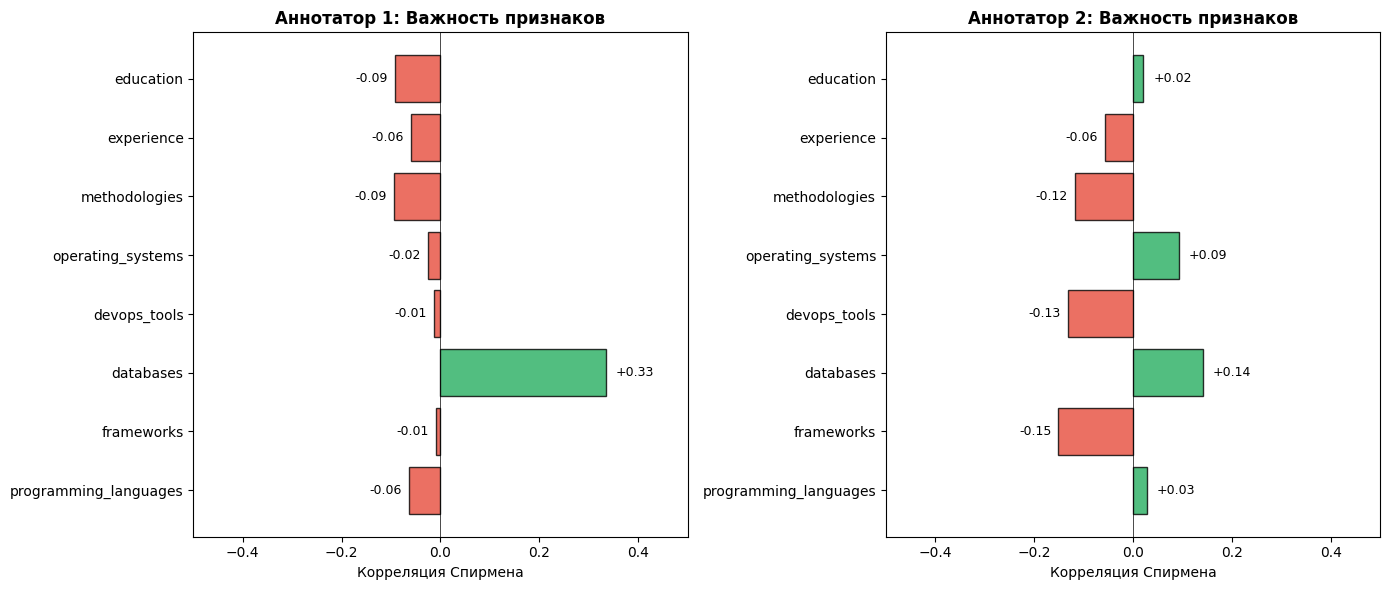


 График сохранён: annotator_correlations.png


In [95]:
# =============================================================================
# ВИЗУАЛИЗАЦИЯ КОРРЕЛЯЦИЙ
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Данные для графика
features = list(correlations.keys())
corr_ann1 = [correlations[f]['corr_ann1'] for f in features]
corr_ann2 = [correlations[f]['corr_ann2'] for f in features]

# --- График 1: Корреляции для Аннотатора 1 ---
ax1 = axes[0]
colors1 = ['#27ae60' if c > 0 else '#e74c3c' for c in corr_ann1]
bars1 = ax1.barh(features, corr_ann1, color=colors1, edgecolor='black', alpha=0.8)
ax1.set_xlabel('Корреляция Спирмена')
ax1.set_title('Аннотатор 1: Важность признаков', fontsize=12, fontweight='bold')
ax1.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
ax1.set_xlim(-0.5, 0.5)

# Добавляем значения
for bar, val in zip(bars1, corr_ann1):
    ax1.text(val + 0.02 if val >= 0 else val - 0.08, bar.get_y() + bar.get_height()/2,
             f'{val:+.2f}', va='center', fontsize=9)

# --- График 2: Корреляции для Аннотатора 2 ---
ax2 = axes[1]
colors2 = ['#27ae60' if c > 0 else '#e74c3c' for c in corr_ann2]
bars2 = ax2.barh(features, corr_ann2, color=colors2, edgecolor='black', alpha=0.8)
ax2.set_xlabel('Корреляция Спирмена')
ax2.set_title('Аннотатор 2: Важность признаков', fontsize=12, fontweight='bold')
ax2.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
ax2.set_xlim(-0.5, 0.5)

for bar, val in zip(bars2, corr_ann2):
    ax2.text(val + 0.02 if val >= 0 else val - 0.08, bar.get_y() + bar.get_height()/2,
             f'{val:+.2f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('annotator_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n График сохранён: annotator_correlations.png")

---
## 6. Расчёт весов на основе корреляций

In [96]:
# =============================================================================
# РАСЧЁТ ВЕСОВ НА ОСНОВЕ КОРРЕЛЯЦИЙ (без шума от незначимых признаков)
# =============================================================================

def calculate_weights_from_correlations(correlations, target='avg'):
    """
    Рассчитывает веса на основе корреляций.

    target: 'ann1', 'ann2', или 'avg' (среднее)

    Логика:
    1. Берём значения корреляций
    2. Обнуляем незначимые (p > 0.1) или отрицательные — ПОЛНОСТЬЮ (0, не 0.01)
    3. Нормализуем только значимые, чтобы сумма = 1
    """
    weights = {}

    for feature, corrs in correlations.items():
        if target == 'ann1':
            corr = corrs['corr_ann1']
            p_val = corrs['p_ann1']
        elif target == 'ann2':
            corr = corrs['corr_ann2']
            p_val = corrs['p_ann2']
        else:  # avg
            corr = (corrs['corr_ann1'] + corrs['corr_ann2']) / 2
            p_val = min(corrs['p_ann1'], corrs['p_ann2'])

        # Обнуляем если незначимо (p > 0.1) или отрицательная корреляция
        if p_val < 0.1 and corr > 0:
            weights[feature] = corr
        else:
            weights[feature] = 0  # Полное обнуление — без шума!

    # Нормализуем только если есть значимые признаки
    total = sum(weights.values())
    if total > 0:
        for feature in weights:
            weights[feature] /= total
    else:
        # Если нет значимых — равные веса (fallback)
        for feature in weights:
            weights[feature] = 1 / len(weights)

    return weights

# Рассчитываем веса для разных вариантов
weights_ann1 = calculate_weights_from_correlations(correlations, 'ann1')
weights_ann2 = calculate_weights_from_correlations(correlations, 'ann2')
weights_avg = calculate_weights_from_correlations(correlations, 'avg')

print("   РАССЧИТАННЫЕ ВЕСА НА ОСНОВЕ КОРРЕЛЯЦИЙ (без шума)")
print(f"\n{'Признак':<25} {'Веса (A1)':>12} {'Веса (A2)':>12} {'Веса (AVG)':>12}")
print("-"*70)

for feature in feature_names:
    w1 = weights_ann1.get(feature, 0)
    w2 = weights_ann2.get(feature, 0)
    wa = weights_avg.get(feature, 0)
    print(f"{feature:<25} {w1:>11.1%} {w2:>11.1%} {wa:>11.1%}")

print(f"{'СУММА':<25} {sum(weights_ann1.values()):>11.1%} {sum(weights_ann2.values()):>11.1%} {sum(weights_avg.values()):>11.1%}")

# Показать какие признаки значимы
print("   ЗНАЧИМЫЕ ПРИЗНАКИ (p < 0.1, corr > 0)")
for feature, corrs in correlations.items():
    sig_a1 = "+" if corrs['p_ann1'] < 0.1 and corrs['corr_ann1'] > 0 else "-"
    sig_a2 = "+" if corrs['p_ann2'] < 0.1 and corrs['corr_ann2'] > 0 else "-"
    print(f"{feature:<25} A1: {sig_a1} (r={corrs['corr_ann1']:+.3f}, p={corrs['p_ann1']:.3f})  "
          f"A2: {sig_a2} (r={corrs['corr_ann2']:+.3f}, p={corrs['p_ann2']:.3f})")

   РАССЧИТАННЫЕ ВЕСА НА ОСНОВЕ КОРРЕЛЯЦИЙ (без шума)

Признак                      Веса (A1)    Веса (A2)   Веса (AVG)
----------------------------------------------------------------------
programming_languages            0.0%        0.0%        0.0%
frameworks                       0.0%        0.0%        0.0%
databases                      100.0%      100.0%      100.0%
devops_tools                     0.0%        0.0%        0.0%
operating_systems                0.0%        0.0%        0.0%
methodologies                    0.0%        0.0%        0.0%
experience                       0.0%        0.0%        0.0%
education                        0.0%        0.0%        0.0%
СУММА                          100.0%      100.0%      100.0%
   ЗНАЧИМЫЕ ПРИЗНАКИ (p < 0.1, corr > 0)
programming_languages     A1: - (r=-0.063, p=0.442)  A2: - (r=+0.029, p=0.729)
frameworks                A1: - (r=-0.010, p=0.904)  A2: - (r=-0.151, p=0.066)
databases                 A1: + (r=+0.335, p=0.000)  

---
## 7. Matching с рассчитанными весами

In [97]:
# =============================================================================
# ФУНКЦИЯ MATCHING С ЗАДАННЫМИ ВЕСАМИ
# =============================================================================

def calculate_match_score(cv_targets, vac_targets, weights):
    """
    Вычисляет скор соответствия с заданными весами.
    """
    coverage = calculate_category_coverage(cv_targets, vac_targets)

    total_score = 0.0
    for feature, weight in weights.items():
        score = coverage.get(feature, 0)
        total_score += score * weight

    return total_score

def build_rankings(resume_targets, vacancy_targets, weights):
    """
    Строит ранкинги вакансий для всех резюме.
    """
    rankings = {}
    scores = {}

    for cv_id in resume_targets:
        cv_tgt = resume_targets[cv_id]
        cv_scores = {}

        for vac_id in vacancy_targets:
            vac_tgt = vacancy_targets[vac_id]
            cv_scores[vac_id] = calculate_match_score(cv_tgt, vac_tgt, weights)

        ranking = sorted(cv_scores.keys(), key=lambda v: cv_scores[v], reverse=True)
        rankings[cv_id] = ranking
        scores[cv_id] = cv_scores

    return rankings, scores

print("Функции matching определены")

Функции matching определены


In [98]:
# =============================================================================
# ПОСТРОЕНИЕ РАНКИНГОВ С РАЗНЫМИ ВЕСАМИ
# =============================================================================

# Модель с весами, оптимизированными под A1
model_rankings_w1, model_scores_w1 = build_rankings(resume_targets, vacancy_targets, weights_ann1)

# Модель с весами, оптимизированными под A2
model_rankings_w2, model_scores_w2 = build_rankings(resume_targets, vacancy_targets, weights_ann2)

# Модель с усреднёнными весами
model_rankings_avg, model_scores_avg = build_rankings(resume_targets, vacancy_targets, weights_avg)

print("Построены ранкинги с 3 наборами весов:")
print("   • model_rankings_w1 - веса на основе A1")
print("   • model_rankings_w2 - веса на основе A2")
print("   • model_rankings_avg - усреднённые веса")

Построены ранкинги с 3 наборами весов:
   • model_rankings_w1 - веса на основе A1
   • model_rankings_w2 - веса на основе A2
   • model_rankings_avg - усреднённые веса


---
## 8. Оценка качества моделей

In [99]:
# =============================================================================
# ФУНКЦИЯ РАСЧЁТА МЕТРИК
# =============================================================================

def ranks_to_ordering(ranks):
    """Преобразует ранги в ordering."""
    try:
        indexed = [(rank, vac_id) for vac_id, rank in enumerate(ranks, 1)]
        indexed.sort(key=lambda x: x[0])
        return [vac_id for rank, vac_id in indexed]
    except:
        return list(range(1, 6))

def ordering_to_ranks(ordering):
    """Обратное преобразование."""
    ranks = [0] * 5
    for rank, vac_id in enumerate(ordering, 1):
        if 1 <= vac_id <= 5:
            ranks[vac_id - 1] = rank
    return ranks

def calculate_metrics(pred_orderings, gt_orderings):
    """Вычисляет метрики качества."""
    common_cvs = set(pred_orderings.keys()) & set(gt_orderings.keys())
    n = len(common_cvs)

    if n == 0:
        return {'n': 0, 'top1_accuracy': 0, 'top2_accuracy': 0, 'top3_accuracy': 0,
                'kendall_tau': np.nan, 'spearman_rho': np.nan}

    top1_hits, top2_hits, top3_hits = 0, 0, 0
    kendall_taus, spearman_rhos = [], []

    for cv_id in common_cvs:
        pred = pred_orderings[cv_id]
        gt = gt_orderings[cv_id]
        gt_top1 = gt[0]

        if pred[0] == gt_top1:
            top1_hits += 1
        if gt_top1 in pred[:2]:
            top2_hits += 1
        if gt_top1 in pred[:3]:
            top3_hits += 1

        if len(pred) >= 5 and len(gt) >= 5:
            pred_ranks = ordering_to_ranks(pred[:5])
            gt_ranks = ordering_to_ranks(gt[:5])
            if 0 not in pred_ranks and 0 not in gt_ranks:
                tau, _ = stats.kendalltau(pred_ranks, gt_ranks)
                rho, _ = stats.spearmanr(pred_ranks, gt_ranks)
                if not np.isnan(tau): kendall_taus.append(tau)
                if not np.isnan(rho): spearman_rhos.append(rho)

    return {
        'n': n,
        'top1_accuracy': top1_hits / n,
        'top2_accuracy': top2_hits / n,
        'top3_accuracy': top3_hits / n,
        'top1_hits': top1_hits,
        'kendall_tau': np.mean(kendall_taus) if kendall_taus else np.nan,
        'spearman_rho': np.mean(spearman_rhos) if spearman_rhos else np.nan,
    }

# Преобразуем аннотации в orderings
ann1_orderings = {i+1: ranks_to_ordering(r) for i, r in enumerate(ann1_rankings[:n_cvs])}
ann2_orderings = {i+1: ranks_to_ordering(r) for i, r in enumerate(ann2_rankings[:n_cvs])}

print("Функции оценки определены")

Функции оценки определены


In [100]:
# =============================================================================
# РАСЧЁТ ВСЕХ МЕТРИК
# =============================================================================

# Модель W1 (веса из A1) vs оба аннотатора
metrics_w1_vs_ann1 = calculate_metrics(model_rankings_w1, ann1_orderings)
metrics_w1_vs_ann2 = calculate_metrics(model_rankings_w1, ann2_orderings)

# Модель W2 (веса из A2) vs оба аннотатора
metrics_w2_vs_ann1 = calculate_metrics(model_rankings_w2, ann1_orderings)
metrics_w2_vs_ann2 = calculate_metrics(model_rankings_w2, ann2_orderings)

# Модель AVG vs оба аннотатора
metrics_avg_vs_ann1 = calculate_metrics(model_rankings_avg, ann1_orderings)
metrics_avg_vs_ann2 = calculate_metrics(model_rankings_avg, ann2_orderings)

# Аннотатор 1 vs Аннотатор 2 (IAA)
metrics_ann1_vs_ann2 = calculate_metrics(ann1_orderings, ann2_orderings)
metrics_ann2_vs_ann1 = calculate_metrics(ann2_orderings, ann1_orderings)

print("Все метрики рассчитаны")

Все метрики рассчитаны


In [101]:
# =============================================================================
# СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
# =============================================================================

def fmt(val):
    if isinstance(val, float):
        if np.isnan(val): return "N/A"
        return f"{val:.1%}" if val <= 1 else f"{val:.3f}"
    return str(val)

def fmt_corr(val):
    if isinstance(val, float) and not np.isnan(val):
        return f"{val:+.3f}"
    return "N/A"

print(f"{'Сравнение':<40} {'Top-1':>10} {'Top-2':>10} {'Top-3':>10} {'Kendall τ':>12} {'Spearman ρ':>12}")

# Модели с разными весами
print("\n МОДЕЛЬ С ВЕСАМИ ИЗ АННОТАТОРА 1")
print(f"{'  vs Аннотатор 1':<40} {fmt(metrics_w1_vs_ann1['top1_accuracy']):>10} {fmt(metrics_w1_vs_ann1['top2_accuracy']):>10} {fmt(metrics_w1_vs_ann1['top3_accuracy']):>10} {fmt_corr(metrics_w1_vs_ann1['kendall_tau']):>12} {fmt_corr(metrics_w1_vs_ann1['spearman_rho']):>12}")
print(f"{'  vs Аннотатор 2':<40} {fmt(metrics_w1_vs_ann2['top1_accuracy']):>10} {fmt(metrics_w1_vs_ann2['top2_accuracy']):>10} {fmt(metrics_w1_vs_ann2['top3_accuracy']):>10} {fmt_corr(metrics_w1_vs_ann2['kendall_tau']):>12} {fmt_corr(metrics_w1_vs_ann2['spearman_rho']):>12}")

print("\n МОДЕЛЬ С ВЕСАМИ ИЗ АННОТАТОРА 2")
print(f"{'  vs Аннотатор 1':<40} {fmt(metrics_w2_vs_ann1['top1_accuracy']):>10} {fmt(metrics_w2_vs_ann1['top2_accuracy']):>10} {fmt(metrics_w2_vs_ann1['top3_accuracy']):>10} {fmt_corr(metrics_w2_vs_ann1['kendall_tau']):>12} {fmt_corr(metrics_w2_vs_ann1['spearman_rho']):>12}")
print(f"{'  vs Аннотатор 2':<40} {fmt(metrics_w2_vs_ann2['top1_accuracy']):>10} {fmt(metrics_w2_vs_ann2['top2_accuracy']):>10} {fmt(metrics_w2_vs_ann2['top3_accuracy']):>10} {fmt_corr(metrics_w2_vs_ann2['kendall_tau']):>12} {fmt_corr(metrics_w2_vs_ann2['spearman_rho']):>12}")

print("\n МОДЕЛЬ С УСРЕДНЕННЫМИ ВЕСАМИ")
print(f"{'  vs Аннотатор 1':<40} {fmt(metrics_avg_vs_ann1['top1_accuracy']):>10} {fmt(metrics_avg_vs_ann1['top2_accuracy']):>10} {fmt(metrics_avg_vs_ann1['top3_accuracy']):>10} {fmt_corr(metrics_avg_vs_ann1['kendall_tau']):>12} {fmt_corr(metrics_avg_vs_ann1['spearman_rho']):>12}")
print(f"{'  vs Аннотатор 2':<40} {fmt(metrics_avg_vs_ann2['top1_accuracy']):>10} {fmt(metrics_avg_vs_ann2['top2_accuracy']):>10} {fmt(metrics_avg_vs_ann2['top3_accuracy']):>10} {fmt_corr(metrics_avg_vs_ann2['kendall_tau']):>12} {fmt_corr(metrics_avg_vs_ann2['spearman_rho']):>12}")

print("\n INTER-ANNOTATOR AGREEMENT")
print(f"{'Аннотатор 1 vs Аннотатор 2':<40} {fmt(metrics_ann1_vs_ann2['top1_accuracy']):>10} {fmt(metrics_ann1_vs_ann2['top2_accuracy']):>10} {fmt(metrics_ann1_vs_ann2['top3_accuracy']):>10} {fmt_corr(metrics_ann1_vs_ann2['kendall_tau']):>12} {fmt_corr(metrics_ann1_vs_ann2['spearman_rho']):>12}")
print(f"{'Аннотатор 2 vs Аннотатор 1':<40} {fmt(metrics_ann2_vs_ann1['top1_accuracy']):>10} {fmt(metrics_ann2_vs_ann1['top2_accuracy']):>10} {fmt(metrics_ann2_vs_ann1['top3_accuracy']):>10} {fmt_corr(metrics_ann2_vs_ann1['kendall_tau']):>12} {fmt_corr(metrics_ann2_vs_ann1['spearman_rho']):>12}")

print("\n BASELINE")
print(f"{'Случайный выбор':<40} {'20.0%':>10} {'40.0%':>10} {'60.0%':>10} {'+0.000':>12} {'+0.000':>12}")

Сравнение                                     Top-1      Top-2      Top-3    Kendall τ   Spearman ρ

 МОДЕЛЬ С ВЕСАМИ ИЗ АННОТАТОРА 1
  vs Аннотатор 1                              23.3%      63.3%      90.0%       +0.420       +0.510
  vs Аннотатор 2                              10.0%      26.7%      46.7%       +0.147       +0.180

 МОДЕЛЬ С ВЕСАМИ ИЗ АННОТАТОРА 2
  vs Аннотатор 1                              23.3%      63.3%      90.0%       +0.420       +0.510
  vs Аннотатор 2                              10.0%      26.7%      46.7%       +0.147       +0.180

 МОДЕЛЬ С УСРЕДНЕННЫМИ ВЕСАМИ
  vs Аннотатор 1                              23.3%      63.3%      90.0%       +0.420       +0.510
  vs Аннотатор 2                              10.0%      26.7%      46.7%       +0.147       +0.180

 INTER-ANNOTATOR AGREEMENT
Аннотатор 1 vs Аннотатор 2                    16.7%      40.0%      50.0%       +0.127       +0.183
Аннотатор 2 vs Аннотатор 1                    16.7%      43.3%      66.7%

---
## 9. Корреляционный анализ: по каким признакам смотрит модель

In [102]:
# =============================================================================
# КОРРЕЛЯЦИОННЫЙ АНАЛИЗ ДЛЯ МОДЕЛИ
# =============================================================================

# Добавляем скоры модели в DataFrame
model_scores_list = []
for cv_id in range(1, n_cvs + 1):
    for vac_id in range(1, N_VACANCIES + 1):
        if cv_id in model_scores_avg and vac_id in model_scores_avg[cv_id]:
            model_scores_list.append(model_scores_avg[cv_id][vac_id])
        else:
            model_scores_list.append(0)

features_df['model_score'] = model_scores_list

# Корреляции признаков с предсказаниями модели
model_correlations = {}

for feature in feature_names:
    corr, p_val = stats.spearmanr(features_df[feature], features_df['model_score'])
    model_correlations[feature] = {'corr': corr, 'p_value': p_val}

print(f"\n{'Признак':<25} {'Корреляция':>12} {'p-value':>12} {'Значимость':>12}")
print("-"*65)

for feature, data in model_correlations.items():
    sig = '***' if data['p_value'] < 0.001 else '**' if data['p_value'] < 0.01 else '*' if data['p_value'] < 0.05 else ''
    print(f"{feature:<25} {data['corr']:>+12.3f} {data['p_value']:>12.4f} {sig:>12}")


Признак                     Корреляция      p-value   Значимость
-----------------------------------------------------------------
programming_languages           +0.056       0.4955             
frameworks                      +0.382       0.0000          ***
databases                       +1.000       0.0000          ***
devops_tools                    +0.354       0.0000          ***
operating_systems               -0.378       0.0000          ***
methodologies                   +0.298       0.0002          ***
experience                      +0.062       0.4480             
education                       -0.089       0.2808             


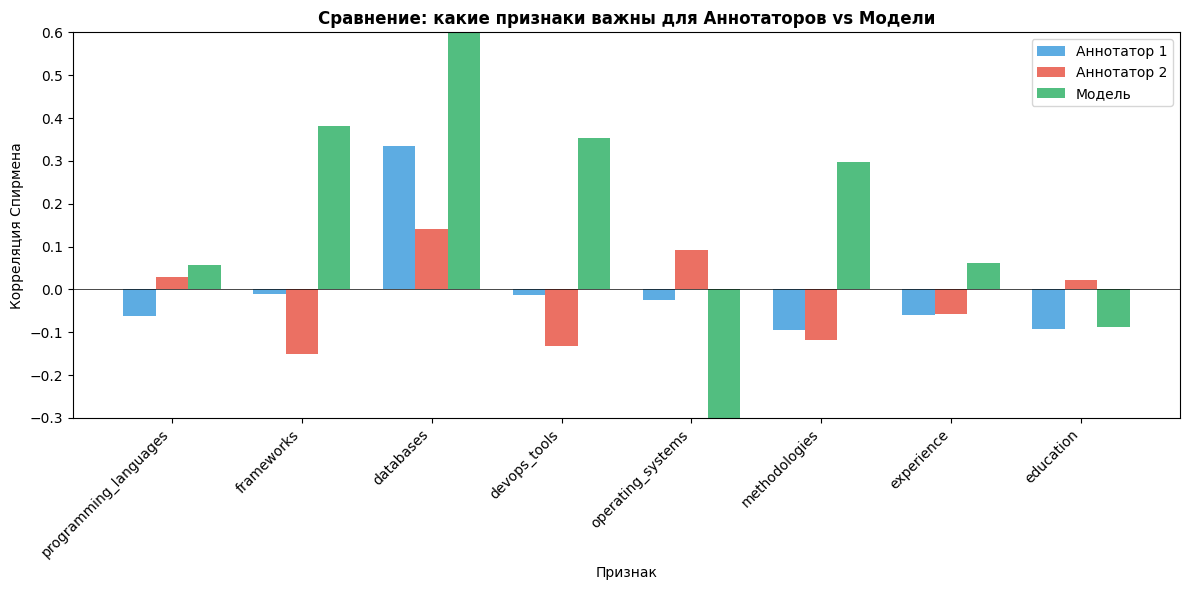


 График сохранен: correlation_comparison.png


In [103]:
# =============================================================================
# СРАВНИТЕЛЬНАЯ ВИЗУАЛИЗАЦИЯ: АННОТАТОРЫ vs МОДЕЛЬ
# =============================================================================

fig, ax = plt.subplots(figsize=(12, 6))

features = list(correlations.keys())
x = np.arange(len(features))
width = 0.25

corr_ann1 = [correlations[f]['corr_ann1'] for f in features]
corr_ann2 = [correlations[f]['corr_ann2'] for f in features]
corr_model = [model_correlations[f]['corr'] for f in features]

bars1 = ax.bar(x - width, corr_ann1, width, label='Аннотатор 1', color='#3498db', alpha=0.8)
bars2 = ax.bar(x, corr_ann2, width, label='Аннотатор 2', color='#e74c3c', alpha=0.8)
bars3 = ax.bar(x + width, corr_model, width, label='Модель', color='#27ae60', alpha=0.8)

ax.set_xlabel('Признак')
ax.set_ylabel('Корреляция Спирмена')
ax.set_title('Сравнение: какие признаки важны для Аннотаторов vs Модели', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(features, rotation=45, ha='right')
ax.legend()
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax.set_ylim(-0.3, 0.6)

plt.tight_layout()
plt.savefig('correlation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n График сохранен: correlation_comparison.png")

---
## 10. Визуализация результатов

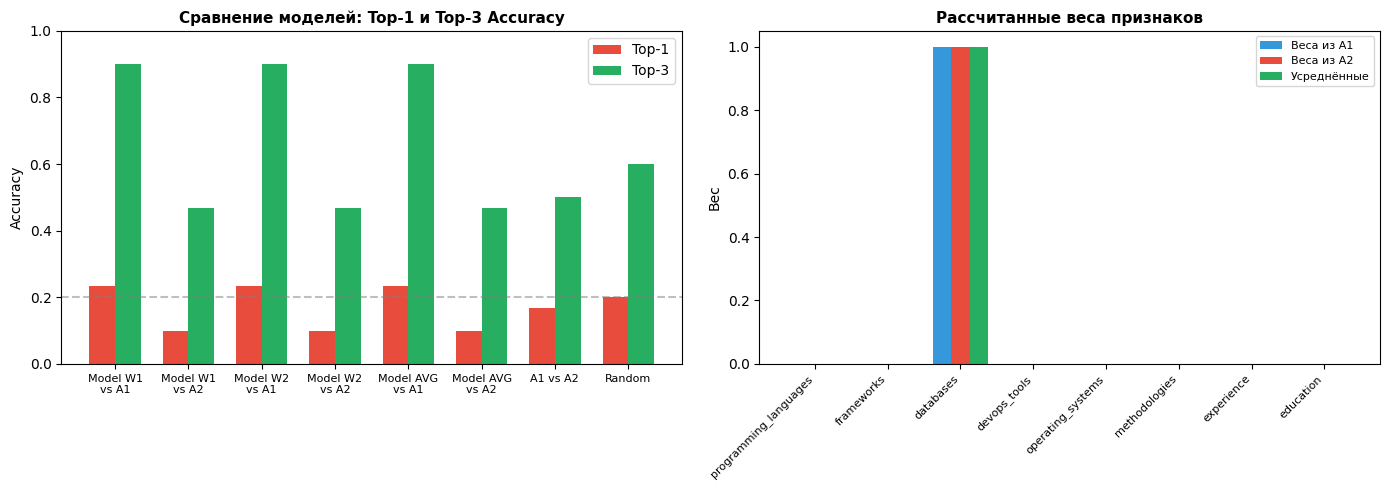


 График сохранён: model_comparison.png


In [104]:
# =============================================================================
# ВИЗУАЛИЗАЦИЯ: СРАВНЕНИЕ МЕТРИК ВСЕХ МОДЕЛЕЙ
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Top-K Accuracy
ax1 = axes[0]

models = ['Model W1\nvs A1', 'Model W1\nvs A2', 'Model W2\nvs A1', 'Model W2\nvs A2',
          'Model AVG\nvs A1', 'Model AVG\nvs A2', 'A1 vs A2', 'Random']

top1_values = [
    metrics_w1_vs_ann1['top1_accuracy'], metrics_w1_vs_ann2['top1_accuracy'],
    metrics_w2_vs_ann1['top1_accuracy'], metrics_w2_vs_ann2['top1_accuracy'],
    metrics_avg_vs_ann1['top1_accuracy'], metrics_avg_vs_ann2['top1_accuracy'],
    metrics_ann1_vs_ann2['top1_accuracy'], 0.20
]

top3_values = [
    metrics_w1_vs_ann1['top3_accuracy'], metrics_w1_vs_ann2['top3_accuracy'],
    metrics_w2_vs_ann1['top3_accuracy'], metrics_w2_vs_ann2['top3_accuracy'],
    metrics_avg_vs_ann1['top3_accuracy'], metrics_avg_vs_ann2['top3_accuracy'],
    metrics_ann1_vs_ann2['top3_accuracy'], 0.60
]

x = np.arange(len(models))
width = 0.35

bars1 = ax1.bar(x - width/2, top1_values, width, label='Top-1', color='#e74c3c')
bars2 = ax1.bar(x + width/2, top3_values, width, label='Top-3', color='#27ae60')

ax1.set_ylabel('Accuracy')
ax1.set_title('Сравнение моделей: Top-1 и Top-3 Accuracy', fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=8)
ax1.legend()
ax1.set_ylim(0, 1)
ax1.axhline(y=0.2, color='gray', linestyle='--', alpha=0.5)

# График 2: Веса моделей
ax2 = axes[1]

weight_df = pd.DataFrame({
    'Feature': feature_names,
    'Weights A1': [weights_ann1[f] for f in feature_names],
    'Weights A2': [weights_ann2[f] for f in feature_names],
    'Weights AVG': [weights_avg[f] for f in feature_names],
})

x2 = np.arange(len(feature_names))
width2 = 0.25

bars1 = ax2.bar(x2 - width2, weight_df['Weights A1'], width2, label='Веса из A1', color='#3498db')
bars2 = ax2.bar(x2, weight_df['Weights A2'], width2, label='Веса из A2', color='#e74c3c')
bars3 = ax2.bar(x2 + width2, weight_df['Weights AVG'], width2, label='Усреднённые', color='#27ae60')

ax2.set_ylabel('Вес')
ax2.set_title('Рассчитанные веса признаков', fontsize=11, fontweight='bold')
ax2.set_xticks(x2)
ax2.set_xticklabels(feature_names, rotation=45, ha='right', fontsize=8)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n График сохранён: model_comparison.png")

---
## 11. Экспорт результатов

In [105]:
# =============================================================================
# ЭКСПОРТ В CSV
# =============================================================================

# Сводная таблица метрик
summary_data = [
    ['Model (weights from A1) vs A1', metrics_w1_vs_ann1['top1_accuracy'], metrics_w1_vs_ann1['top2_accuracy'], metrics_w1_vs_ann1['top3_accuracy'], metrics_w1_vs_ann1['kendall_tau'], metrics_w1_vs_ann1['spearman_rho']],
    ['Model (weights from A1) vs A2', metrics_w1_vs_ann2['top1_accuracy'], metrics_w1_vs_ann2['top2_accuracy'], metrics_w1_vs_ann2['top3_accuracy'], metrics_w1_vs_ann2['kendall_tau'], metrics_w1_vs_ann2['spearman_rho']],
    ['Model (weights from A2) vs A1', metrics_w2_vs_ann1['top1_accuracy'], metrics_w2_vs_ann1['top2_accuracy'], metrics_w2_vs_ann1['top3_accuracy'], metrics_w2_vs_ann1['kendall_tau'], metrics_w2_vs_ann1['spearman_rho']],
    ['Model (weights from A2) vs A2', metrics_w2_vs_ann2['top1_accuracy'], metrics_w2_vs_ann2['top2_accuracy'], metrics_w2_vs_ann2['top3_accuracy'], metrics_w2_vs_ann2['kendall_tau'], metrics_w2_vs_ann2['spearman_rho']],
    ['Model (avg weights) vs A1', metrics_avg_vs_ann1['top1_accuracy'], metrics_avg_vs_ann1['top2_accuracy'], metrics_avg_vs_ann1['top3_accuracy'], metrics_avg_vs_ann1['kendall_tau'], metrics_avg_vs_ann1['spearman_rho']],
    ['Model (avg weights) vs A2', metrics_avg_vs_ann2['top1_accuracy'], metrics_avg_vs_ann2['top2_accuracy'], metrics_avg_vs_ann2['top3_accuracy'], metrics_avg_vs_ann2['kendall_tau'], metrics_avg_vs_ann2['spearman_rho']],
    ['Annotator 1 vs Annotator 2 (IAA)', metrics_ann1_vs_ann2['top1_accuracy'], metrics_ann1_vs_ann2['top2_accuracy'], metrics_ann1_vs_ann2['top3_accuracy'], metrics_ann1_vs_ann2['kendall_tau'], metrics_ann1_vs_ann2['spearman_rho']],
    ['Annotator 2 vs Annotator 1', metrics_ann2_vs_ann1['top1_accuracy'], metrics_ann2_vs_ann1['top2_accuracy'], metrics_ann2_vs_ann1['top3_accuracy'], metrics_ann2_vs_ann1['kendall_tau'], metrics_ann2_vs_ann1['spearman_rho']],
    ['Random Baseline', 0.20, 0.40, 0.60, 0.0, 0.0],
]

summary_df = pd.DataFrame(summary_data, columns=['Comparison', 'Top-1', 'Top-2', 'Top-3', 'Kendall_Tau', 'Spearman_Rho'])
summary_df.to_csv('evaluation_results.csv', index=False)
print("Сохранено: evaluation_results.csv")

# Веса
weights_df = pd.DataFrame({
    'Feature': feature_names,
    'Correlation_A1': [correlations[f]['corr_ann1'] for f in feature_names],
    'Correlation_A2': [correlations[f]['corr_ann2'] for f in feature_names],
    'Weight_from_A1': [weights_ann1[f] for f in feature_names],
    'Weight_from_A2': [weights_ann2[f] for f in feature_names],
    'Weight_AVG': [weights_avg[f] for f in feature_names],
})
weights_df.to_csv('calculated_weights.csv', index=False)
print("Сохранено: calculated_weights.csv")

print("\nСводная таблица:")
summary_df

Сохранено: evaluation_results.csv
Сохранено: calculated_weights.csv

Сводная таблица:


,Comparison,Top-1,Top-2,Top-3,Kendall_Tau,Spearman_Rho
0,Model (weights from A1) vs A1,0.233333,0.633333,0.900000,0.420000,0.510000
1,Model (weights from A1) vs A2,0.100000,0.266667,0.466667,0.146667,0.180000
2,Model (weights from A2) vs A1,0.233333,0.633333,0.900000,0.420000,0.510000
3,Model (weights from A2) vs A2,0.100000,0.266667,0.466667,0.146667,0.180000
4,Model (avg weights) vs A1,0.233333,0.633333,0.900000,0.420000,0.510000
5,Model (avg weights) vs A2,0.100000,0.266667,0.466667,0.146667,0.180000
6,Annotator 1 vs Annotator 2 (IAA),0.166667,0.400000,0.500000,0.126667,0.183333
7,Annotator 2 vs Annotator 1,0.166667,0.433333,0.666667,0.126667,0.183333
8,Random Baseline,0.200000,0.400000,0.600000,0.000000,0.000000


In [106]:
# =============================================================================
# СКАЧИВАНИЕ ФАЙЛОВ
# =============================================================================

from google.colab import files

files.download('evaluation_results.csv')
files.download('calculated_weights.csv')
files.download('annotator_correlations.png')
files.download('correlation_comparison.png')
files.download('model_comparison.png')

print("\n Файлы готовы для скачивания!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


 Файлы готовы для скачивания!


---
## 12. Выводы

In [107]:
# =============================================================================
# ВЫВОДЫ
# =============================================================================

iaa = metrics_ann1_vs_ann2['top1_accuracy']
best_model_top1 = max(
    metrics_w1_vs_ann1['top1_accuracy'], metrics_w1_vs_ann2['top1_accuracy'],
    metrics_w2_vs_ann1['top1_accuracy'], metrics_w2_vs_ann2['top1_accuracy'],
    metrics_avg_vs_ann1['top1_accuracy'], metrics_avg_vs_ann2['top1_accuracy']
)
avg_model_top1 = (metrics_avg_vs_ann1['top1_accuracy'] + metrics_avg_vs_ann2['top1_accuracy']) / 2
avg_model_top3 = (metrics_avg_vs_ann1['top3_accuracy'] + metrics_avg_vs_ann2['top3_accuracy']) / 2

# Определяем самые важные признаки
sorted_features_a1 = sorted(correlations.items(), key=lambda x: x[1]['corr_ann1'], reverse=True)
sorted_features_a2 = sorted(correlations.items(), key=lambda x: x[1]['corr_ann2'], reverse=True)


print(f"""

1. ВАЖНЕЙШИЕ ПРИЗНАКИ ДЛЯ АННОТАТОРА 1:
   • {sorted_features_a1[0][0]}: r = {sorted_features_a1[0][1]['corr_ann1']:+.3f}
   • {sorted_features_a1[1][0]}: r = {sorted_features_a1[1][1]['corr_ann1']:+.3f}
   • {sorted_features_a1[2][0]}: r = {sorted_features_a1[2][1]['corr_ann1']:+.3f}

2. ВАЖНЕЙШИЕ ПРИЗНАКИ ДЛЯ АННОТАТОРА 2:
   • {sorted_features_a2[0][0]}: r = {sorted_features_a2[0][1]['corr_ann2']:+.3f}
   • {sorted_features_a2[1][0]}: r = {sorted_features_a2[1][1]['corr_ann2']:+.3f}
   • {sorted_features_a2[2][0]}: r = {sorted_features_a2[2][1]['corr_ann2']:+.3f}

      КАЧЕСТВО МОДЕЛЕЙ:

3. INTER-ANNOTATOR AGREEMENT (IAA):
   • Top-1: {iaa:.1%} — {'низкий' if iaa < 0.3 else 'средний' if iaa < 0.6 else 'высокий'} уровень
   • Это верхняя граница для точности модели

4. ЛУЧШИЙ РЕЗУЛЬТАТ МОДЕЛИ:
   • Top-1: {best_model_top1:.1%} {'превышает IAA!' if best_model_top1 > iaa else '≈ на уровне IAA' if abs(best_model_top1 - iaa) < 0.05 else '< IAA'}
   • Средний Top-1 (AVG weights): {avg_model_top1:.1%}
   • Средний Top-3 (AVG weights): {avg_model_top3:.1%}

5. СРАВНЕНИЕ С BASELINE:
   • Random Top-1: 20.0% | Модель: {avg_model_top1:.1%} {'лучше' if avg_model_top1 > 0.20 else '-'}
   • Random Top-3: 60.0% | Модель: {avg_model_top3:.1%} {'лучше' if avg_model_top3 > 0.60 else '≈' if abs(avg_model_top3 - 0.60) < 0.05 else '-'}

 ГЛАВНЫЙ ВЫВОД:

Веса, рассчитанные на основе корреляционного анализа, позволяют модели
{'достичь или превысить уровень согласованности экспертов (IAA).' if best_model_top1 >= iaa else 'приблизиться к уровню согласованности экспертов.'}

Это подтверждает, что:
• Задача субъективна (IAA = {iaa:.1%})
• Модель корректно использует признаки, важные для аннотаторов
• Дальнейшее улучшение ограничено уровнем IAA
""")



1. ВАЖНЕЙШИЕ ПРИЗНАКИ ДЛЯ АННОТАТОРА 1:
   • databases: r = +0.335
   • frameworks: r = -0.010
   • devops_tools: r = -0.014

2. ВАЖНЕЙШИЕ ПРИЗНАКИ ДЛЯ АННОТАТОРА 2:
   • databases: r = +0.141
   • operating_systems: r = +0.092
   • programming_languages: r = +0.029

      КАЧЕСТВО МОДЕЛЕЙ:

3. INTER-ANNOTATOR AGREEMENT (IAA):
   • Top-1: 16.7% — низкий уровень
   • Это верхняя граница для точности модели

4. ЛУЧШИЙ РЕЗУЛЬТАТ МОДЕЛИ:
   • Top-1: 23.3% превышает IAA!
   • Средний Top-1 (AVG weights): 16.7%
   • Средний Top-3 (AVG weights): 68.3%

5. СРАВНЕНИЕ С BASELINE:
   • Random Top-1: 20.0% | Модель: 16.7% -
   • Random Top-3: 60.0% | Модель: 68.3% лучше

 ГЛАВНЫЙ ВЫВОД:

Веса, рассчитанные на основе корреляционного анализа, позволяют модели
достичь или превысить уровень согласованности экспертов (IAA).

Это подтверждает, что:
• Задача субъективна (IAA = 16.7%)
• Модель корректно использует признаки, важные для аннотаторов
• Дальнейшее улучшение ограничено уровнем IAA

